# <font color='gold'> Segmentation des clients d'un grossiste

**Jeu de données :** Wholesale customers — UCI Machine Learning Repository

**Lien :** [https://archive.ics.uci.edu/dataset/292/wholesale+customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers)

### <font color='gold'> Import les librairies requises

In [1]:
# Importer  packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
 # Supprimer les warnings
 import warnings
 warnings.filterwarnings('ignore')

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


###<font color='gold'> Importer et lire les données

In [5]:
# Importer data
df = pd.read_csv("/content/drive/MyDrive/Machine Learning/EXAMEN ML/Wholesale_Customers/Wholesale_customers_data.csv")

#### Description des variables du jeu de données "Wholesale customers" (UCI)

Ce jeu de données contient les dépenses annuelles (en unités monétaires) de 440 clients d'un grossiste au Portugal, pour différentes catégories de produits. L'objectif est d'effectuer une segmentation (clustering) des clients pour identifier des groupes homogènes.

| Variable | Type | Description |
|----------|------|-------------|
| `Channel` | Numérique | Canal du client : 1 = Horeca (hôtels, restaurants, cafés), 2 = Commerce de détail. |
| `Region` | Numérique | Région du client : 1 = Lisbonne, 2 = Porto, 3 = Autre. |
| `Fresh` | Numérique | Dépenses annuelles en produits frais. |
| `Milk` | Numérique | Dépenses annuelles en produits laitiers. |
| `Grocery` | Numérique | Dépenses annuelles en épicerie. |
| `Frozen` | Numérique | Dépenses annuelles en produits surgelés. |
| `Detergents_Paper` | Numérique | Dépenses annuelles en détergents et produits papier. |
| `Delicassen` | Numérique | Dépenses annuelles en produits d'épicerie fine. |

Les données ne contiennent ni valeurs manquantes ni doublons : aucun nettoyage n'est nécessaire.

In [6]:
# Afficher les données
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [7]:
# Dimension des données
df.shape

(440, 8)

In [8]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [9]:
# décrire les données
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### <font color='gold'> Preparation des données

In [10]:
# renommer les index
df.index = ['Client' + str(i+1) for i in range(len(df))]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Client1,2,3,12669,9656,7561,214,2674,1338
Client2,2,3,7057,9810,9568,1762,3293,1776
Client3,2,3,6353,8808,7684,2405,3516,7844
Client4,1,3,13265,1196,4221,6404,507,1788
Client5,2,3,22615,5410,7198,3915,1777,5185


In [12]:
import joblib as jb
jb.dump(df.columns.tolist(),"/content/drive/MyDrive/Machine Learning/EXAMEN ML/Wholesale_Customers/colonnes.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML/Wholesale_Customers/colonnes.joblib']

In [13]:
# Données en format matriciel
x = df.values
x[:5]

array([[    2,     3, 12669,  9656,  7561,   214,  2674,  1338],
       [    2,     3,  7057,  9810,  9568,  1762,  3293,  1776],
       [    2,     3,  6353,  8808,  7684,  2405,  3516,  7844],
       [    1,     3, 13265,  1196,  4221,  6404,   507,  1788],
       [    2,     3, 22615,  5410,  7198,  3915,  1777,  5185]])

In [14]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)
x[:5]

array([[1.11821406e-04, 1.67732109e-04, 7.08332695e-01, 5.39873747e-01,
        4.22740825e-01, 1.19648904e-02, 1.49505220e-01, 7.48085205e-02],
       [1.25321880e-04, 1.87982820e-04, 4.42198253e-01, 6.14703821e-01,
        5.99539873e-01, 1.10408576e-01, 2.06342475e-01, 1.11285829e-01],
       [1.24839188e-04, 1.87258782e-04, 3.96551681e-01, 5.49791784e-01,
        4.79632161e-01, 1.50119124e-01, 2.19467293e-01, 4.89619296e-01],
       [6.45937822e-05, 1.93781347e-04, 8.56836521e-01, 7.72541635e-02,
        2.72650355e-01, 4.13658581e-01, 3.27490476e-02, 1.15493683e-01],
       [7.91877886e-05, 1.18781683e-04, 8.95415919e-01, 2.14202968e-01,
        2.84996851e-01, 1.55010096e-01, 7.03583502e-02, 2.05294342e-01]])

In [15]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca_model= PCA(n_components = 2)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice features_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])

In [16]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(82.8)

### <font color='gold'> Kmeans

In [17]:
# Importer KMeans
from sklearn.cluster import KMeans

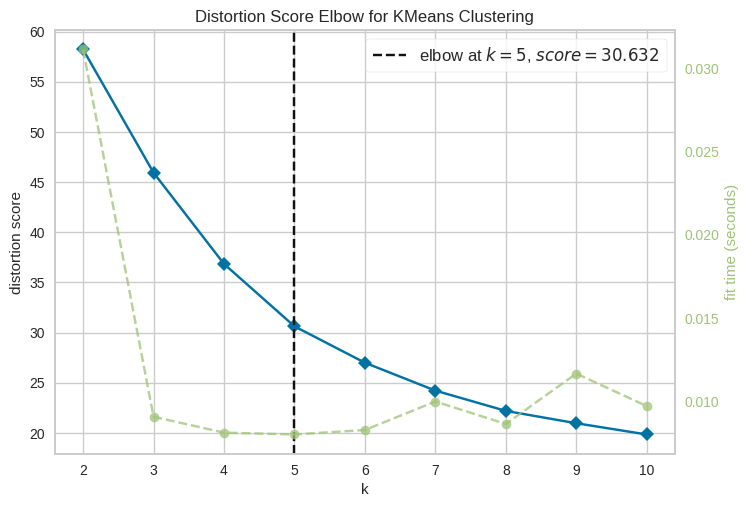

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [18]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

In [58]:
# instantier le modèle
kmeans_model = KMeans(n_clusters=3,init="random",max_iter=500)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=3)

#### <font color='teal'> Prédiction

In [59]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition[:100]

array([2, 0, 0, 2, 2, 2, 2, 0, 0, 0, 0, 2, 2, 2, 2, 2, 0, 0, 2, 0, 2, 1,
       2, 0, 2, 2, 2, 2, 0, 2, 2, 0, 2, 2, 0, 0, 2, 0, 0, 2, 2, 2, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 2, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 1, 0,
       0, 2, 1, 2, 1, 0, 1, 2, 0, 2, 1, 0, 2, 0, 2, 0, 0, 2, 2, 0, 0, 2,
       1, 2, 2, 1, 0, 1, 0, 0, 0, 1, 1, 1], dtype=int32)

In [60]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
print(val)

2    210
0    177
1     53
Name: count, dtype: int64


In [61]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [62]:
# visualion le diagramme des nombres d'observations
bar_plot(val)

In [63]:
# Function de visualisuation des classes
def scatter_plot(New_df,Pred):
  fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

In [64]:
# Visualiser les classes
scatter_plot(New_df,kmeans_partition)

##### <font color='teal'> Indice de silhouette de la partition du Kmeans

In [65]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_kmeans = silhouette_score(x,kmeans_partition)
print(f"La silhouette: {sil_kmeans} ")

La silhouette: 0.4490241274990781 


### <font color='gold'> CAH

In [66]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

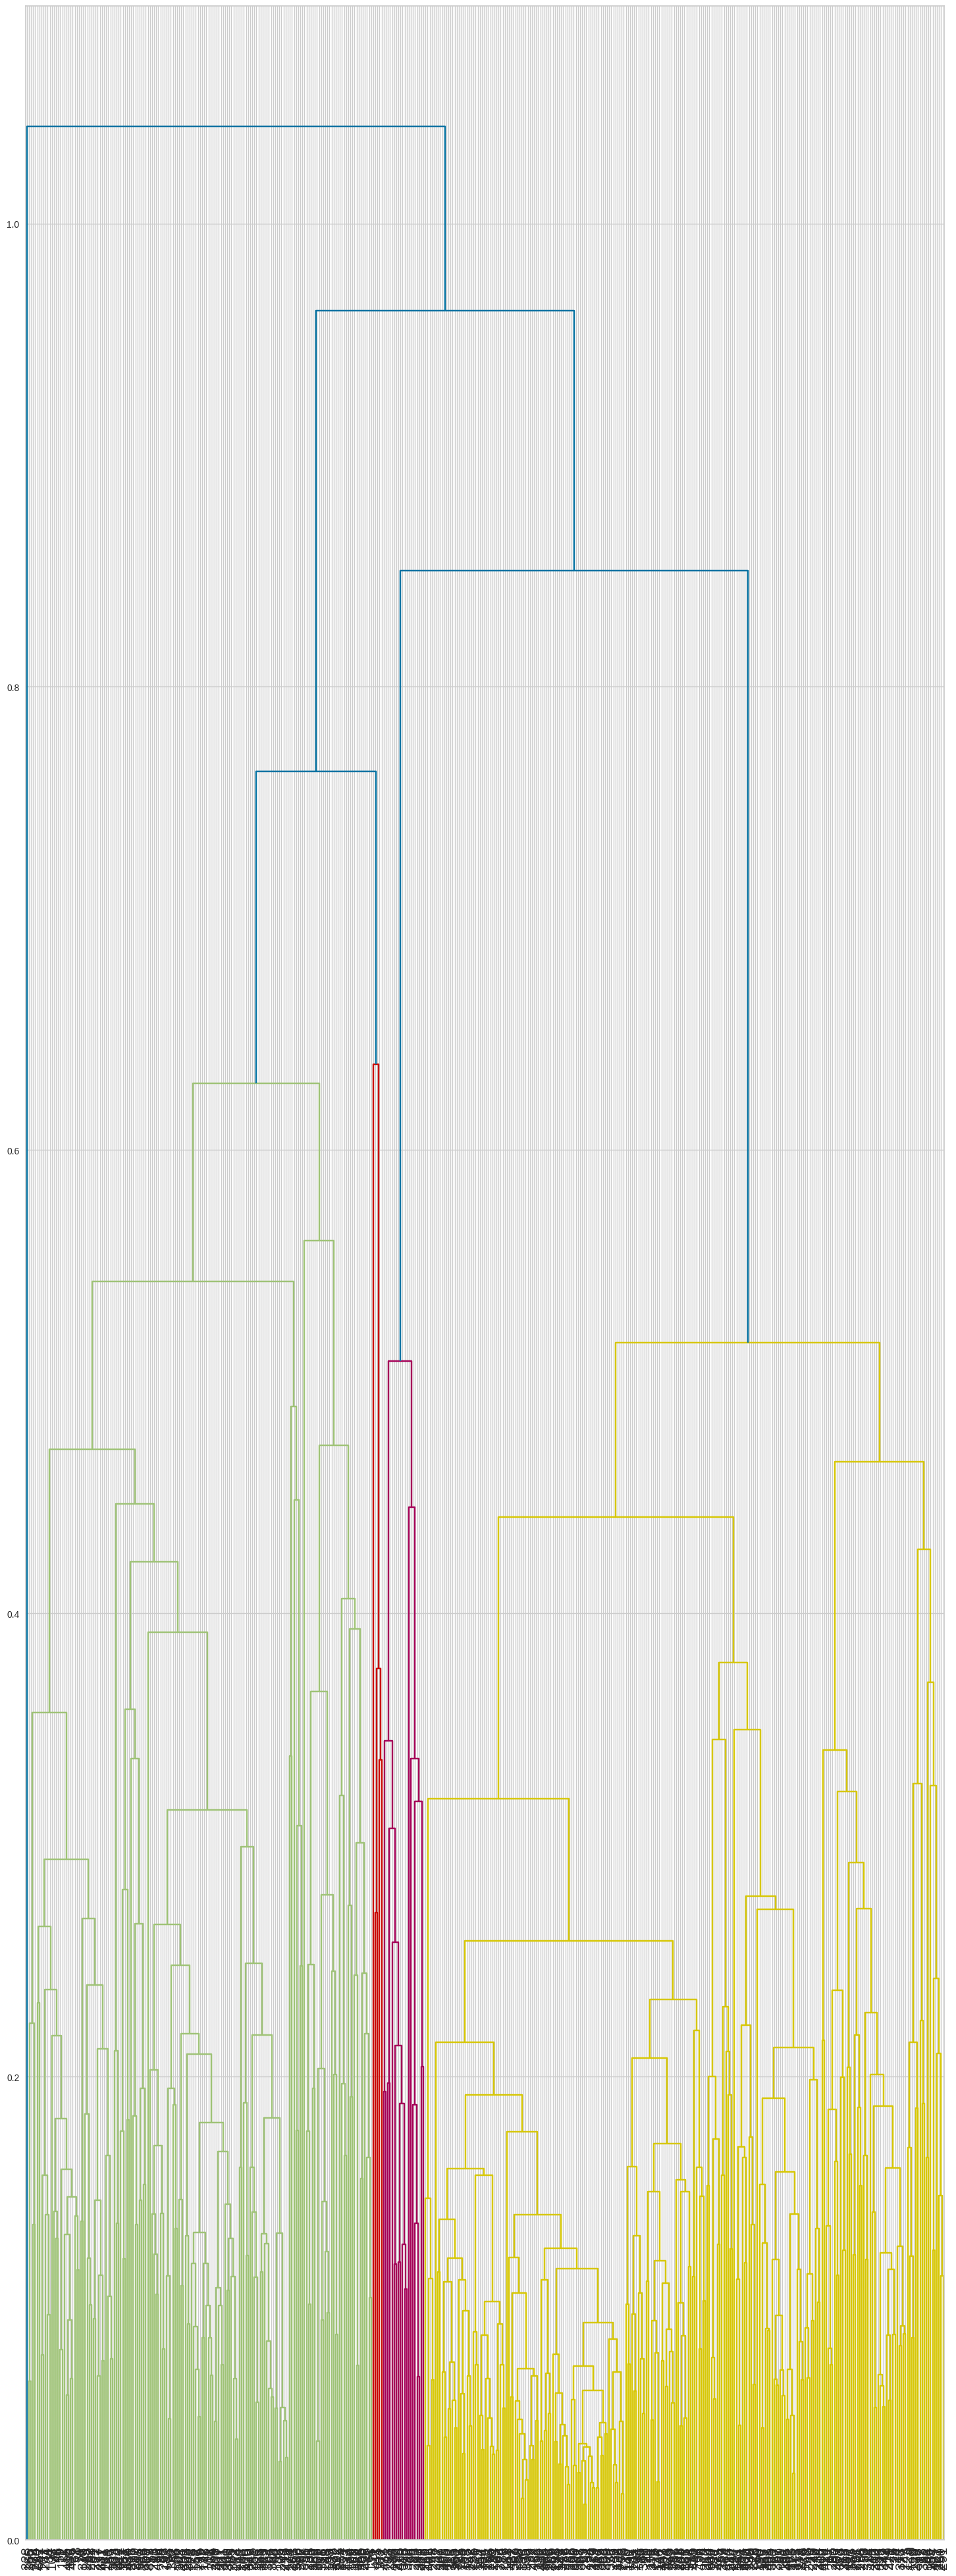

In [67]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [97]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters=3,linkage="average")
# Entrainer le modèle
cah_model.fit(x)

AgglomerativeClustering(linkage='average', n_clusters=3)

In [98]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[:100]

array([0, 2, 2, 0, 0, 0, 0, 2, 2, 2, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 2, 2, 0, 2, 2, 0, 0, 0, 2, 2,
       2, 2, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       2, 0, 2, 0, 0, 2, 0, 0, 2, 0, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 2, 0,
       0, 0, 0, 0, 2, 0, 2, 2, 2, 0, 0, 0])

In [99]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

,count
0,269
2,170
1,1


In [100]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [101]:
# Visualiser les classes
scatter_plot(New_df,cah_partition)

In [102]:
# Silhouette score
sil_cah = silhouette_score(x,cah_partition)
print(f"La silhouette: {sil_cah} ")

La silhouette: 0.48136429766223626 


In [103]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [104]:
# les indidivus
cluster_names = []
for i in range(3):
 cluster_names.append(list(df.index[cah_partition== i]))

In [105]:
# Les individus de la classe 0
print(cluster_names[0])

['Client1', 'Client4', 'Client5', 'Client6', 'Client7', 'Client12', 'Client13', 'Client14', 'Client15', 'Client16', 'Client18', 'Client19', 'Client20', 'Client21', 'Client22', 'Client23', 'Client24', 'Client25', 'Client26', 'Client27', 'Client28', 'Client30', 'Client31', 'Client33', 'Client34', 'Client37', 'Client40', 'Client41', 'Client42', 'Client51', 'Client53', 'Client55', 'Client59', 'Client61', 'Client63', 'Client65', 'Client68', 'Client70', 'Client71', 'Client73', 'Client74', 'Client76', 'Client77', 'Client79', 'Client81', 'Client84', 'Client85', 'Client88', 'Client89', 'Client90', 'Client91', 'Client92', 'Client94', 'Client98', 'Client99', 'Client100', 'Client104', 'Client105', 'Client106', 'Client111', 'Client113', 'Client114', 'Client115', 'Client116', 'Client117', 'Client118', 'Client119', 'Client120', 'Client121', 'Client122', 'Client123', 'Client124', 'Client125', 'Client126', 'Client127', 'Client128', 'Client130', 'Client131', 'Client132', 'Client133', 'Client134', 'Clien

### <font color='gold'> Déploiement du meilleur modèle (CAH)

In [106]:
import numpy as np
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(cah_partition)
centroides = np.array([x[cah_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouveau):
    obs = normalize(np.array(nouveau, dtype=float).reshape(1, -1))
    distances = cdist(obs, centroides)
    return classes[distances.argmin()]

In [107]:
jb.dump(centroides,"/content/drive/MyDrive/Machine Learning/EXAMEN ML/Wholesale_Customers/centroides.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML/Wholesale_Customers/centroides.joblib']

In [108]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[0].values))
print("Classe réelle de la CAH:", cah_partition[0])

Classe prédite  : 0
Classe réelle de la CAH: 0


#### <font color='teal'> Interpréter les classes

In [109]:
# Profil moyen de chaque classe
profil = df.groupby(cah_partition).mean().round(2)
profil

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.14,2.55,16597.55,3249.99,4065.38,3940.06,874.80,1326.37
1,1.00,1.00,1869.00,577.00,572.00,950.00,4762.00,203.00
2,1.61,2.54,4785.42,9856.07,14143.55,1710.72,6045.73,1846.75


In [110]:
# Noms des classes
noms_classes = {
    0: "Gros acheteurs de produits frais",
    1: "Client atypique",
    2: "Gros acheteurs d'épicerie",
}

In [111]:
jb.dump(noms_classes,"/content/drive/MyDrive/Machine Learning/EXAMEN ML//Wholesale_Customers/noms_classes.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML//Wholesale_Customers/noms_classes.joblib']